# Week 4: Dynamic Capacity Utilization Curves

In [1]:
import numpy as np
import pandas as pd
pd.options.mode.chained_assignment = None 
import pickle

import os
from importlib import reload

import matplotlib.pyplot as plt
import matplotlib 
# import seaborn as sns
%matplotlib inline
plt.style.use('ggplot')
from matplotlib.ticker import MultipleLocator

### load competition data and show some stats

In [2]:
results_dir = os.path.join("..", "..", "results")

# Récupération de tous les fichiers CSV dans le dossier results
file_paths = [
    os.path.join(results_dir, f)
    for f in os.listdir(results_dir)
    if f.startswith("duopoly_competition_details") and f.endswith(".csv")
]

# Fusion et suppression des doublons
df_comp_details = pd.concat(
    [pd.read_csv(f) for f in file_paths], ignore_index=True
)
df_comp_details.drop_duplicates(inplace=True)

# Traitement des valeurs manquantes et calcul du revenu
df_comp_details.fillna(0, inplace=True)
df_comp_details["revenue"] = (
    df_comp_details["price"] * df_comp_details["demand"]
)

df_comp_details.head(3)

# 1. Nombre de fichiers détectés
print(f"Nombre de fichiers trouvés : {len(file_paths)}\n")

# 2. Somme des lignes individuelles
total_lignes = sum(len(pd.read_csv(f)) for f in file_paths)

print(f"Somme des lignes des 4 fichiers : {total_lignes}")
print(
    f"Lignes dans df_comp_details (avant nettoyage) : {len(df_comp_details)}"
)

Nombre de fichiers trouvés : 4

Somme des lignes des 4 fichiers : 200000
Lignes dans df_comp_details (avant nettoyage) : 200000


In [3]:
df_comp_details.groupby(['competitor_id','competition_id']).agg({
    'price' : 'mean',
    'price_competitor' : 'mean',
    'revenue' : 'sum'
}).round(1)

price  price_competitor   revenue
competitor_id     competition_id                                   
BlueFalcon        3RCuyb           49.7              48.9  266059.7
CarrotHyrax       4JTdQL           45.6              53.9  260568.8
                  tm3HD8           79.9              54.7  320960.5
ElectricButterfly 3p8o46           32.0              24.4      30.0
FierceDuck        3zfMB8           28.1              26.3  100217.9
HospitableBeaver  339UBs           81.6              27.6    3005.0
IncredibleDogfish 4EGbSk           69.3              56.8  367028.0
KickassMoth       45cC4i           81.7             100.1  455912.4
PinkDuck          3AHQ52           58.5             100.0  185607.9
                  PnCp2V           63.3              99.9  237229.5
RadiantBird       37Xuwp           77.8              11.5     700.0
                  45GaaD           75.6              12.3   23721.5
SeriousLori       3j5toq           23.2              20.1   54503.9
                  5a2kVz           25.9              25.5   97247.4
TestedBobcat      3erHqy           60.3              61.7  328087.0
                  VgXDDB           54.9              56.9  302639.4
TopazCat          3sm8DC           26.7              24.8   85234.9
                  FHYYKp           26.3              20.5   71194.0
UnbiasedCurassow  4EWNCR           78.4              76.3  466705.2
                  8GTkrF           31.5              33.9       0.0

In [4]:
df_comp_details['unique_selling_season_key'] = df_comp_details.apply(lambda r:
                                "%s_%s" % (r.competition_id,r.selling_season), axis=1)

In [5]:
dfx_rev = df_comp_details.groupby('unique_selling_season_key').agg({
    'revenue' : 'sum'
}).reset_index()
dfx_rev.head(3)

,unique_selling_season_key,revenue
0,339UBs_1,0.0
1,339UBs_10,30.0
2,339UBs_100,90.0


array([[<Axes: title={'center': 'revenue'}>]], dtype=object)

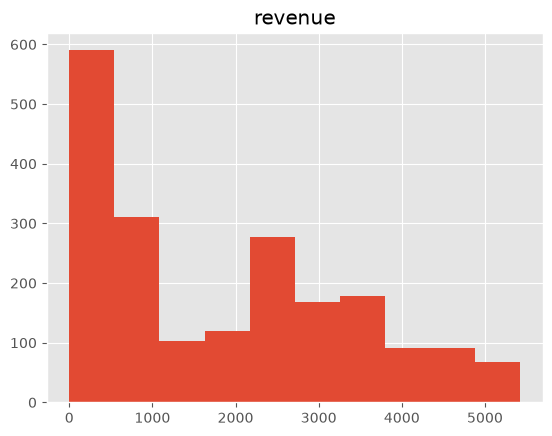

In [6]:
dfx_rev.hist()

## show the capacity utilization curve

In [7]:
dfp_util = pd.pivot_table(df_comp_details, 
                        values='demand', 
                        index=['selling_period'],
                        columns=['unique_selling_season_key'], 
                        aggfunc="mean")

# loop over columns to compute the % utilization
for c in dfp_util.columns:
    dfp_util[c] = dfp_util[c].cumsum()
    dfp_util[c] = round(dfp_util[c] / 80, 2)
    
dfp_util.tail()

unique_selling_season_key,339UBs_1,339UBs_10,339UBs_100,339UBs_11,339UBs_12,339UBs_13,339UBs_14,339UBs_15,339UBs_16,339UBs_17,...,tm3HD8_90,tm3HD8_91,tm3HD8_92,tm3HD8_93,tm3HD8_94,tm3HD8_95,tm3HD8_96,tm3HD8_97,tm3HD8_98,tm3HD8_99
selling_period,,,,,,,,,,,,,,,,,,,,,
96,0.0,0.01,0.04,0.01,0.02,0.0,0.01,0.0,0.0,0.0,...,0.88,0.86,0.89,0.74,0.78,0.74,0.88,0.7,0.88,0.85
97,0.0,0.01,0.04,0.01,0.02,0.0,0.01,0.0,0.0,0.0,...,0.88,0.86,0.89,0.74,0.78,0.74,0.88,0.7,0.88,0.85
98,0.0,0.01,0.04,0.01,0.02,0.0,0.01,0.0,0.0,0.0,...,0.88,0.86,0.89,0.74,0.78,0.74,0.88,0.7,0.88,0.85
99,0.0,0.01,0.04,0.01,0.02,0.0,0.01,0.0,0.0,0.0,...,0.88,0.86,0.89,0.74,0.78,0.74,0.88,0.7,0.88,0.85
100,0.0,0.01,0.04,0.01,0.02,0.0,0.01,0.0,0.0,0.0,...,0.88,0.86,0.89,0.74,0.78,0.74,0.88,0.7,0.88,0.85


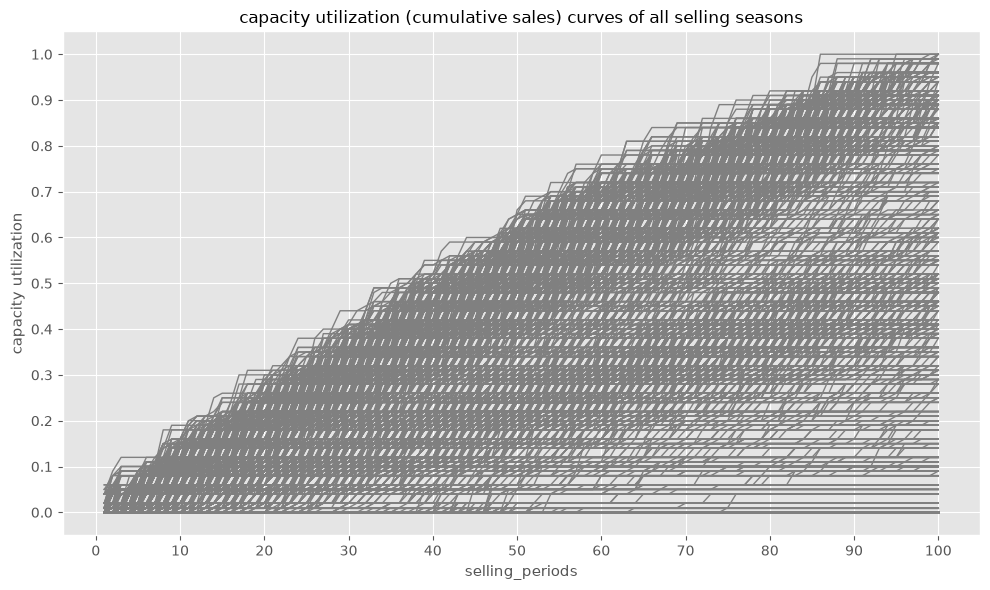

In [8]:
fig, ax = plt.subplots(figsize=(10,6))

ax.plot(dfp_util.index, dfp_util, color='grey', 
        linestyle='-', linewidth=1, )
ax.set_xlabel('selling_periods', size=11)
# ax.set_xticks(np.arange(min(dft.index), max(dft.index)+1, 1.0))
ax.set_ylabel("capacity utilization" , size=11)

y_majorLocator = MultipleLocator(0.1)
ax.yaxis.set_major_locator(y_majorLocator)
x_majorLocator = MultipleLocator(10)
ax.xaxis.set_major_locator(x_majorLocator)

ax.set_title("capacity utilization (cumulative sales) curves of all selling seasons", size=12)
# ax.legend(loc=0)

ax.grid(True)
fig.tight_layout()

plt.show()

# (1) build target capacity utilization curve based on top 20% revenue selling seasons

In [9]:
dfx_rev.revenue.quantile(0.8)

np.float64(3375.9000000000005)

In [10]:
top_selling_seasons = dfx_rev[dfx_rev.revenue>=dfx_rev.revenue.quantile(0.8)].unique_selling_season_key.unique()
top_selling_seasons[:10]

<StringArray>
['3RCuyb_16', '3RCuyb_20', '3RCuyb_23', '3RCuyb_26', '3RCuyb_36', '3RCuyb_37',
 '3RCuyb_38', '3RCuyb_68', '3RCuyb_85', '3RCuyb_98']
Length: 10, dtype: str

In [11]:
dfp_top_curves = dfp_util[top_selling_seasons]
dfp_top_curves.shape

(100, 400)

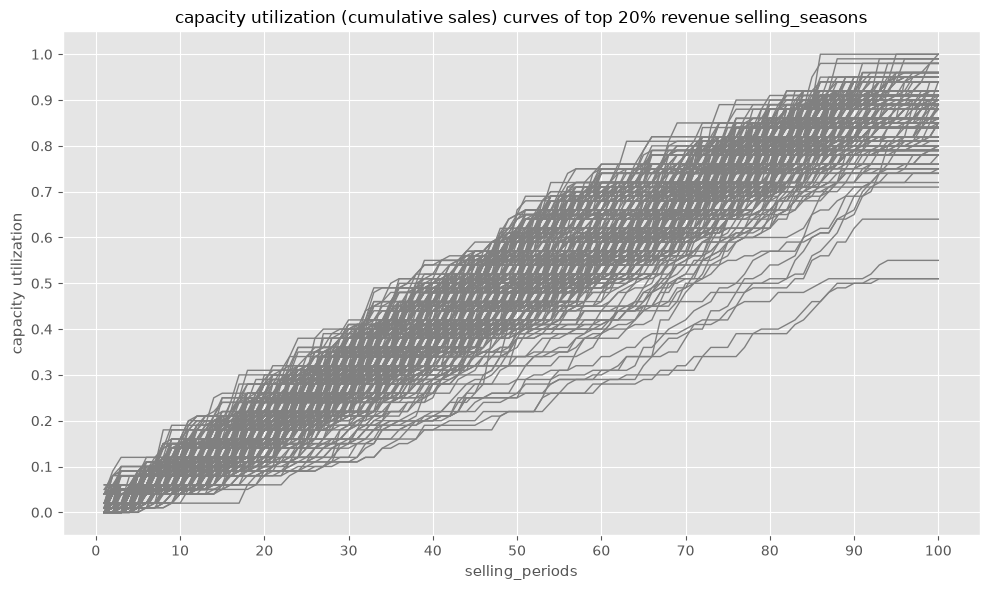

In [12]:
fig, ax = plt.subplots(figsize=(10,6))

ax.plot(dfp_top_curves.index, dfp_top_curves, color='grey', 
        linestyle='-', linewidth=1, )
ax.set_xlabel('selling_periods', size=11)
# ax.set_xticks(np.arange(min(dft.index), max(dft.index)+1, 1.0))
ax.set_ylabel("capacity utilization" , size=11)

y_majorLocator = MultipleLocator(0.1)
ax.yaxis.set_major_locator(y_majorLocator)
x_majorLocator = MultipleLocator(10)
ax.xaxis.set_major_locator(x_majorLocator)

ax.set_title("capacity utilization (cumulative sales) curves of top 20% revenue selling_seasons", size=12)
# ax.legend(loc=0)

ax.grid(True)
fig.tight_layout()

plt.show()

C:\Users\creep\AppData\Local\Temp\ipykernel_26760\3794927001.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dfp_top_curves['mean_curve'] = dfp_top_curves.apply(lambda r: np.mean(r), axis=1)


<Axes: xlabel='selling_period'>

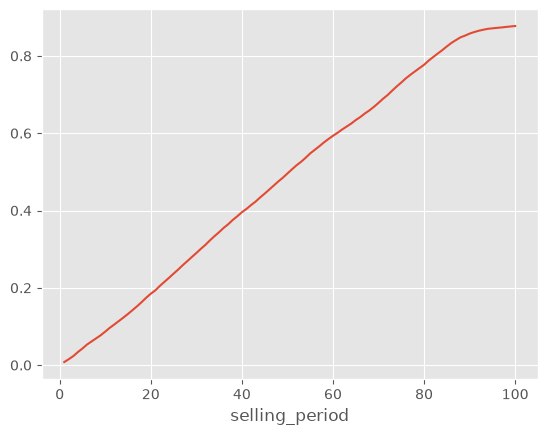

In [13]:
dfp_top_curves['mean_curve'] = dfp_top_curves.apply(lambda r: np.mean(r), axis=1)
dfp_top_curves['mean_curve'].plot()

In [14]:
target_sales_curve = {}
for t in np.arange(1,101,5):
    target = {}
    target['cap_util'] = round(dfp_top_curves.loc[t,'mean_curve'],2)
    target['sold_seats'] = round(dfp_top_curves.loc[t,'mean_curve'] * 80)
    target_sales_curve[str(t)] = target
    
target_sales_curve

{'1': {'cap_util': np.float64(0.01), 'sold_seats': 1},
 '6': {'cap_util': np.float64(0.05), 'sold_seats': 4},
 '11': {'cap_util': np.float64(0.1), 'sold_seats': 8},
 '16': {'cap_util': np.float64(0.14), 'sold_seats': 11},
 '21': {'cap_util': np.float64(0.19), 'sold_seats': 15},
 '26': {'cap_util': np.float64(0.25), 'sold_seats': 20},
 '31': {'cap_util': np.float64(0.3), 'sold_seats': 24},
 '36': {'cap_util': np.float64(0.36), 'sold_seats': 28},
 '41': {'cap_util': np.float64(0.4), 'sold_seats': 32},
 '46': {'cap_util': np.float64(0.45), 'sold_seats': 36},
 '51': {'cap_util': np.float64(0.51), 'sold_seats': 41},
 '56': {'cap_util': np.float64(0.56), 'sold_seats': 45},
 '61': {'cap_util': np.float64(0.6), 'sold_seats': 48},
 '66': {'cap_util': np.float64(0.64), 'sold_seats': 51},
 '71': {'cap_util': np.float64(0.69), 'sold_seats': 55},
 '76': {'cap_util': np.float64(0.74), 'sold_seats': 59},
 '81': {'cap_util': np.float64(0.79), 'sold_seats': 63},
 '86': {'cap_util': np.float64(0.83), 's

In [15]:
# save to pickle
with open('target_sales_curve.pkl', "wb") as f:
    pickle.dump(target_sales_curve, f, protocol=pickle.HIGHEST_PROTOCOL)

In [16]:
# load from pickle
with open('target_sales_curve.pkl', 'rb') as f:
            target_curve = pickle.load(f)
target_curve

{'1': {'cap_util': np.float64(0.01), 'sold_seats': 1},
 '6': {'cap_util': np.float64(0.05), 'sold_seats': 4},
 '11': {'cap_util': np.float64(0.1), 'sold_seats': 8},
 '16': {'cap_util': np.float64(0.14), 'sold_seats': 11},
 '21': {'cap_util': np.float64(0.19), 'sold_seats': 15},
 '26': {'cap_util': np.float64(0.25), 'sold_seats': 20},
 '31': {'cap_util': np.float64(0.3), 'sold_seats': 24},
 '36': {'cap_util': np.float64(0.36), 'sold_seats': 28},
 '41': {'cap_util': np.float64(0.4), 'sold_seats': 32},
 '46': {'cap_util': np.float64(0.45), 'sold_seats': 36},
 '51': {'cap_util': np.float64(0.51), 'sold_seats': 41},
 '56': {'cap_util': np.float64(0.56), 'sold_seats': 45},
 '61': {'cap_util': np.float64(0.6), 'sold_seats': 48},
 '66': {'cap_util': np.float64(0.64), 'sold_seats': 51},
 '71': {'cap_util': np.float64(0.69), 'sold_seats': 55},
 '76': {'cap_util': np.float64(0.74), 'sold_seats': 59},
 '81': {'cap_util': np.float64(0.79), 'sold_seats': 63},
 '86': {'cap_util': np.float64(0.83), 's

# (2) Build randomized versions of the target capacity utilization curve

**idea:**

- estimate from the given curve the distribution of slope-steps
- draw random samples from this curve and use this to build new curves



In [17]:
df = pd.DataFrame(columns=['selling_period','perc_sales_target'])
for i in target_curve.keys():
    df.loc[len(df)] = [i, target_curve.get(i).get('cap_util') ]

df.head(10)

,selling_period,perc_sales_target
0,1,0.01
1,6,0.05
2,11,0.10
3,16,0.14
4,21,0.19
5,26,0.25
6,31,0.30
7,36,0.36
8,41,0.40
9,46,0.45


## (a) estimate the slope increases of the target curve as delta every 5 time periods

In [18]:
df['shifted_target'] = df['perc_sales_target'].shift(1)
df.head(3)

,selling_period,perc_sales_target,shifted_target
0,1,0.01,NaN
1,6,0.05,0.01
2,11,0.10,0.05


## (b) show the distribution (histogram) of the 5-step target increases

<Axes: >

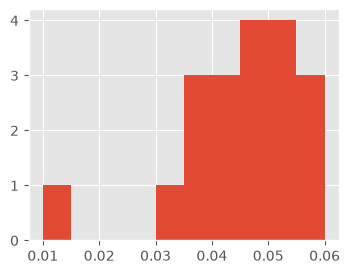

In [19]:
df['5day_delta'] =  df['perc_sales_target'] - df['shifted_target']

df['5day_delta'].hist(figsize=(4,3))

## (c) fit a normal distribution to these delta-values

In [20]:
delta_values = df['5day_delta'].dropna().values
delta_values

array([0.04, 0.05, 0.04, 0.05, 0.06, 0.05, 0.06, 0.04, 0.05, 0.06, 0.05,
       0.04, 0.04, 0.05, 0.05, 0.05, 0.04, 0.03, 0.01])

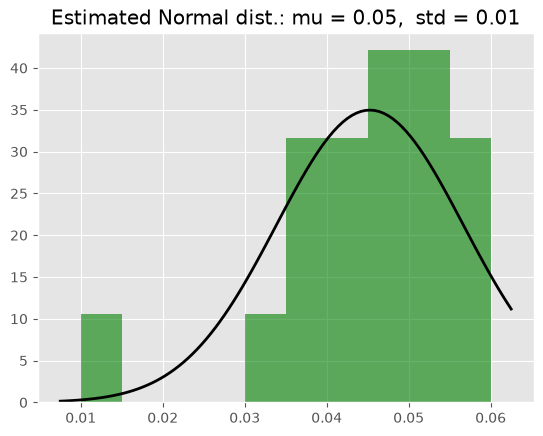

In [21]:
from scipy.stats import norm

# Fit a normal distribution to the data:
mu, std = norm.fit(delta_values)

# Plot the histogram.
plt.hist(delta_values, density=True, alpha=0.6, color='g')

# Plot the PDF.
xmin, xmax = plt.xlim()
x = np.linspace(xmin, xmax, 100)
p = norm.pdf(x, mu, std)
plt.plot(x, p, 'k', linewidth=2)
title = "Estimated Normal dist.: mu = %.2f,  std = %.2f" % (mu, std)
plt.title(title)

plt.show()

## (d) use distribution to fit new curves

In [22]:
norm.rvs(loc=mu, scale=std, size=20)

array([0.03251349, 0.0184662 , 0.04225338, 0.03772333, 0.04900008,
       0.0432545 , 0.0526118 , 0.03275958, 0.04012358, 0.07662579,
       0.0458234 , 0.06449678, 0.05420413, 0.04198489, 0.03144695,
       0.03615074, 0.03861293, 0.03790238, 0.04924696, 0.06543369])

<Axes: >

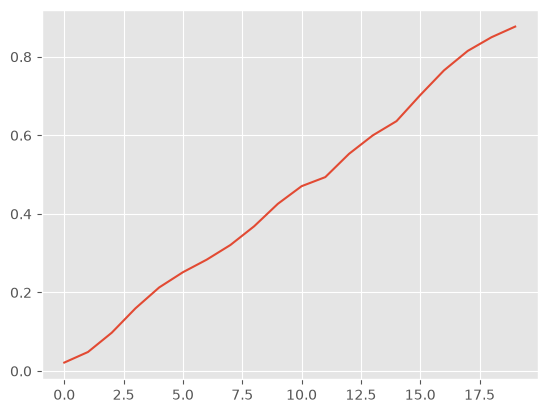

In [23]:
# generate random steps
df['sample_curve_1'] = norm.rvs(loc=mu, scale=std, size=20)
# aggregate the new random price curve
df['sample_curve_1'] = df['sample_curve_1'].cumsum()
# replace any value above 1 with 1, note that .where replaces the not holding False situations
df['sample_curve_1'] = df['sample_curve_1'].where(df['sample_curve_1'] < 1, 1.0)

df['sample_curve_1'].plot()

#### plot random curve vs. input target curve

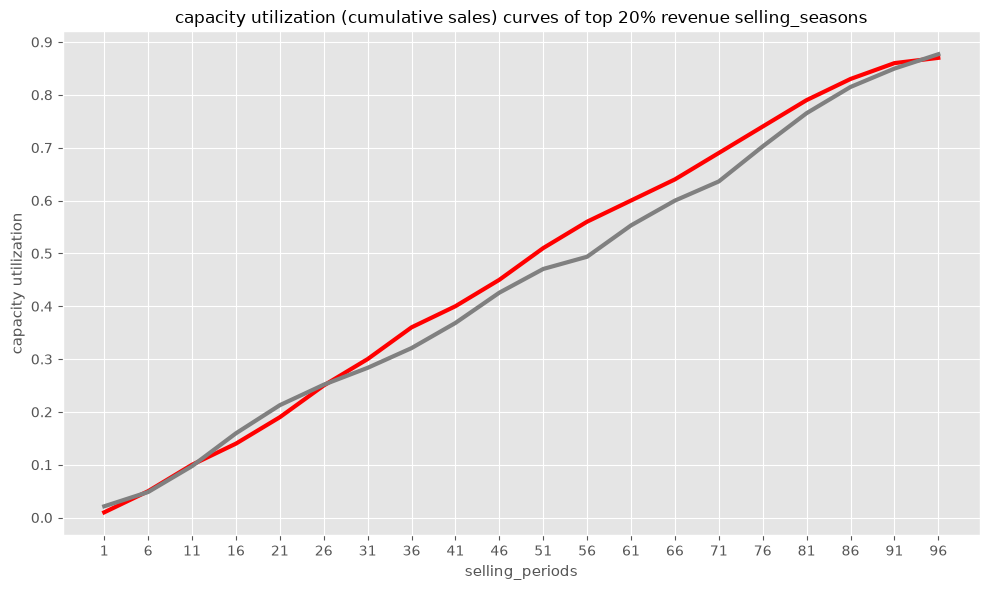

In [24]:
# plt.figure(figsize=(10, 6))
# plt.plot(df.index, df['sample_curve_1'], label='Random Curve')
# plt.plot(df.index, df['perc_sales_target'], label='Input Curve')
# plt.xlabel('Index')
# plt.ylabel('Values')
# plt.title('Two Curves Comparison')
# plt.legend()
# plt.grid(True)
# plt.show()
fig, ax = plt.subplots(figsize=(10,6))

ax.plot(df['selling_period'], df['perc_sales_target'], color='r', 
        linestyle='-', linewidth=3, label='org curve')

ax.plot(df['selling_period'], df['sample_curve_1'], color='grey', 
        linestyle='-', linewidth=3, label='random curve')

ax.set_xlabel('selling_periods', size=11)
# ax.set_xticks(np.arange(min(dft.index), max(dft.index)+1, 1.0))
ax.set_ylabel("capacity utilization" , size=11)

y_majorLocator = MultipleLocator(0.1)
ax.yaxis.set_major_locator(y_majorLocator)

ax.set_title("capacity utilization (cumulative sales) curves of top 20% revenue selling_seasons", size=12)

ax.grid(True)
fig.tight_layout()

plt.show()